<a href="https://colab.research.google.com/github/jaeheechillin3/pytorch_projects/blob/main/simple_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

## Configuration

In [2]:
DATASET = "kmnist"
DATA_ROOT = "./data"
IMAGE_SIZE = 32
IMAGE_CHANNELS = 1
TRAIN_SAMPLES = 10_000    # Set to None to train on the full training split.
BASE_CHANNELS = 32
BATCH_SIZE = 32
TIMESTEPS = 1000
EPOCHS = 30               # Set to 100 for longer training.
LEARNING_RATE = 1e-4
SAMPLE_EVERY = 5
OUTPUT_DIR = "./kmnist_diffusion_outputs"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Helper Functions

In [3]:
def load_dataset():
    """Download KMNIST and optionally select a reproducible training subset."""
    transform = transforms.Compose([
        # Padding preserves character strokes and yields dimensions divisible by 16.
        transforms.Pad(2, fill=0),
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5,), std=(0.5,)),
    ])
    dataset = datasets.KMNIST(
        DATA_ROOT, train=True, transform=transform, download=True
    )
    if TRAIN_SAMPLES is None:
        return dataset
    if not 1 <= TRAIN_SAMPLES <= len(dataset):
        raise ValueError(f"TRAIN_SAMPLES must be between 1 and {len(dataset)}.")
    generator = torch.Generator().manual_seed(42)
    indices = torch.randperm(len(dataset), generator=generator)[:TRAIN_SAMPLES]
    return Subset(dataset, indices.tolist())

In [4]:
def show_images(images, title=None, save_path=None):
    """Display a CHW image or BCHW batch normalized to [-1, 1]."""
    if images.ndim == 3:
        images = images.unsqueeze(0)
    images = (images.detach().cpu().float() / 2 + 0.5).clamp(0, 1)
    count = len(images)
    cols = min(5, count)
    rows = math.ceil(count / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, image in zip(axes.flat, images):
        if image.shape[0] == 1:
            axis.imshow(image[0], cmap="gray", vmin=0, vmax=1)
        else:
            axis.imshow(image.permute(1, 2, 0))
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Model

In [5]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        if dim < 4 or dim % 2:
            raise ValueError("Time embedding dimension must be even and >= 4.")
        half_dim = dim // 2
        frequencies = torch.exp(
            -math.log(10_000) * torch.arange(half_dim) / (half_dim - 1)
        )
        self.register_buffer("frequencies", frequencies)

    def forward(self, time):
        angles = time.float()[:, None] * self.frequencies[None, :]
        return torch.cat((angles.sin(), angles.cos()), dim=-1)

In [6]:
class Block(nn.Module):
    """Two convolutions with timestep conditioning, then down/up-sampling."""
    def __init__(self, in_channels, out_channels, time_dim, up=False):
        super().__init__()
        input_channels = 2 * in_channels if up else in_channels
        self.conv1 = nn.Conv2d(input_channels, out_channels, 3, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        # GroupNorm does not depend on batch statistics during sampling.
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.time_mlp = nn.Sequential(nn.SiLU(), nn.Linear(time_dim, out_channels))
        if up:
            self.resample = nn.ConvTranspose2d(out_channels, out_channels, 4, 2, 1)
        else:
            self.resample = nn.Conv2d(out_channels, out_channels, 4, 2, 1)

    def forward(self, x, time_embedding):
        x = F.silu(self.norm1(self.conv1(x)))
        x = x + self.time_mlp(time_embedding)[:, :, None, None]
        x = F.silu(self.norm2(self.conv2(x)))
        return self.resample(x)

In [7]:
class SimpleUnet(nn.Module):
    def __init__(self, image_channels=3, base_channels=32, time_dim=32):
        super().__init__()
        if base_channels < 8 or base_channels % 8:
            raise ValueError("base_channels must be a positive multiple of 8.")
        channels = [base_channels * factor for factor in (1, 2, 4, 8, 16)]
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
        )
        self.conv0 = nn.Conv2d(image_channels, channels[0], 3, padding=1)
        self.downs = nn.ModuleList([
            Block(channels[i], channels[i + 1], time_dim) for i in range(4)
        ])
        self.ups = nn.ModuleList([
            Block(channels[i], channels[i - 1], time_dim, up=True)
            for i in range(4, 0, -1)
        ])
        self.output = nn.Conv2d(channels[0], image_channels, 1)

    def forward(self, x, time):
        if x.shape[-2] % 16 or x.shape[-1] % 16:
            raise ValueError("Image height and width must be divisible by 16.")
        time_embedding = self.time_mlp(time)
        x = self.conv0(x)
        skips = []
        for down in self.downs:
            x = down(x, time_embedding)
            skips.append(x)
        for up in self.ups:
            x = torch.cat((x, skips.pop()), dim=1)
            x = up(x, time_embedding)
        return self.output(x)

In [8]:
class Diffusion(nn.Module):
    """DDPM schedule and forward/reverse processes; buffers follow .to(device)."""
    def __init__(self, timesteps=1000):
        super().__init__()
        if timesteps < 2:
            raise ValueError("timesteps must be >= 2.")
        self.timesteps = timesteps
        betas = torch.linspace(1e-4, 0.02, timesteps)
        alphas = 1 - betas
        alpha_bar = torch.cumprod(alphas, dim=0)
        alpha_bar_previous = F.pad(alpha_bar[:-1], (1, 0), value=1.0)
        coefficients = {
            "sqrt_alpha_bar": alpha_bar.sqrt(),
            "sqrt_one_minus_alpha_bar": (1 - alpha_bar).sqrt(),
            "posterior_mean_x0": betas * alpha_bar_previous.sqrt() / (1 - alpha_bar),
            "posterior_mean_xt": (
                (1 - alpha_bar_previous) * alphas.sqrt() / (1 - alpha_bar)
            ),
            "posterior_variance": (
                betas * (1 - alpha_bar_previous) / (1 - alpha_bar)
            ),
        }
        for name, values in coefficients.items():
            self.register_buffer(name, values)

    @staticmethod
    def extract(values, time, x):
        return values.gather(0, time).reshape(-1, *([1] * (x.ndim - 1)))

    def forward_diffusion_sample(self, clean_images, time, noise=None):
        if noise is None:
            noise = torch.randn_like(clean_images)
        noisy_images = (
            self.extract(self.sqrt_alpha_bar, time, clean_images) * clean_images
            + self.extract(self.sqrt_one_minus_alpha_bar, time, clean_images) * noise
        )
        return noisy_images, noise

    def loss(self, model, clean_images, time):
        noisy_images, noise = self.forward_diffusion_sample(clean_images, time)
        return F.mse_loss(model(noisy_images, time), noise)

    @torch.no_grad()
    def sample_timestep(self, model, x, time):
        predicted_noise = model(x, time)
        # Clip the estimated clean image, NOT the noisy intermediate state.
        predicted_x0 = (
            (x - self.extract(self.sqrt_one_minus_alpha_bar, time, x) * predicted_noise)
            / self.extract(self.sqrt_alpha_bar, time, x)
        ).clamp(-1, 1)
        mean = (
            self.extract(self.posterior_mean_x0, time, x) * predicted_x0
            + self.extract(self.posterior_mean_xt, time, x) * x
        )
        variance = self.extract(self.posterior_variance, time, x)
        nonzero = (time > 0).reshape(-1, *([1] * (x.ndim - 1)))
        return mean + nonzero * variance.sqrt() * torch.randn_like(x)

    @torch.no_grad()
    def sample(self, model, shape, initial_noise=None):
        was_training = model.training
        model.eval()
        try:
            device = self.sqrt_alpha_bar.device
            if initial_noise is None:
                x = torch.randn(shape, device=device)
            else:
                x = initial_noise.to(device).clone()
            if tuple(x.shape) != tuple(shape):
                raise ValueError("initial_noise must match the requested shape.")
            for step in reversed(range(self.timesteps)):
                time = torch.full((shape[0],), step, device=device, dtype=torch.long)
                x = self.sample_timestep(model, x, time)
            return x
        finally:
            model.train(was_training)

## Training

In [9]:
def main():
    torch.manual_seed(42)
    output_dir = Path(OUTPUT_DIR)
    output_dir.mkdir(parents=True, exist_ok=True)
    dataset = load_dataset()
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
        pin_memory=DEVICE.type == "cuda",
    )
    model = SimpleUnet(IMAGE_CHANNELS, BASE_CHANNELS).to(DEVICE)
    diffusion = Diffusion(TIMESTEPS).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    sample_shape = (5, IMAGE_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
    fixed_noise = torch.randn(sample_shape, device=DEVICE)
    print(f"Device: {DEVICE} | Training images: {len(dataset):,}")
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

    show_images(torch.stack([dataset[i][0] for i in range(5)]), "Training examples")
    clean_image = dataset[0][0].unsqueeze(0).to(DEVICE)
    times = torch.linspace(0, TIMESTEPS - 1, 10, device=DEVICE).long()
    # Reuse one noise realization so the forward-process comparison is clearer.
    noise = torch.randn_like(clean_image).expand(10, -1, -1, -1)
    noisy, _ = diffusion.forward_diffusion_sample(
        clean_image.expand(10, -1, -1, -1), times, noise
    )
    show_images(noisy, "Forward diffusion: increasing noise (left to right, top to bottom)")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        total_images = 0
        for images, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            time = torch.randint(TIMESTEPS, (images.size(0),), device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = diffusion.loss(model, images, time)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            total_images += images.size(0)
        history.append(total_loss / total_images)
        print(f"Epoch {epoch:3d}/{EPOCHS} | Noise MSE: {history[-1]:.5f}", flush=True)

        # Save before sampling so training progress survives plotting failures.
        torch.save({
            "model": model.state_dict(), "diffusion": diffusion.state_dict(),
            "optimizer": optimizer.state_dict(), "epoch": epoch, "history": history,
            "config": {
                "dataset": DATASET, "image_size": IMAGE_SIZE,
                "image_channels": IMAGE_CHANNELS, "base_channels": BASE_CHANNELS,
                "timesteps": TIMESTEPS, "train_samples": TRAIN_SAMPLES,
            },
        }, output_dir / "checkpoint.pt")
        if epoch % SAMPLE_EVERY == 0 or epoch == EPOCHS:
            samples = diffusion.sample(model, sample_shape, fixed_noise)
            show_images(
                samples,
                f"Generated images: epoch {epoch}",
                output_dir / f"samples_{epoch:03d}.png",
            )

    fig, axis = plt.subplots(figsize=(7, 4))
    axis.plot(range(1, EPOCHS + 1), history)
    axis.set(xlabel="Epoch", ylabel="Noise-prediction MSE", title="Training loss")
    axis.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_dir / "training_loss.png")
    plt.show()
    plt.close(fig)
    return model, diffusion, history

100%|██████████| 18.2M/18.2M [00:10<00:00, 1.76MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 452kB/s]
100%|██████████| 3.04M/3.04M [00:01<00:00, 2.84MB/s]
100%|██████████| 5.12k/5.12k [00:00<00:00, 10.3MB/s]


Device: cuda | Training images: 10,000
Parameters: 15,639,169


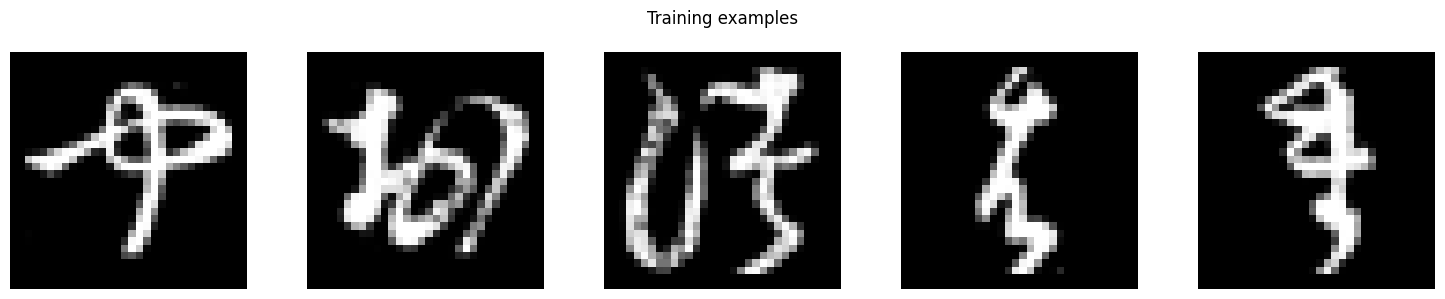

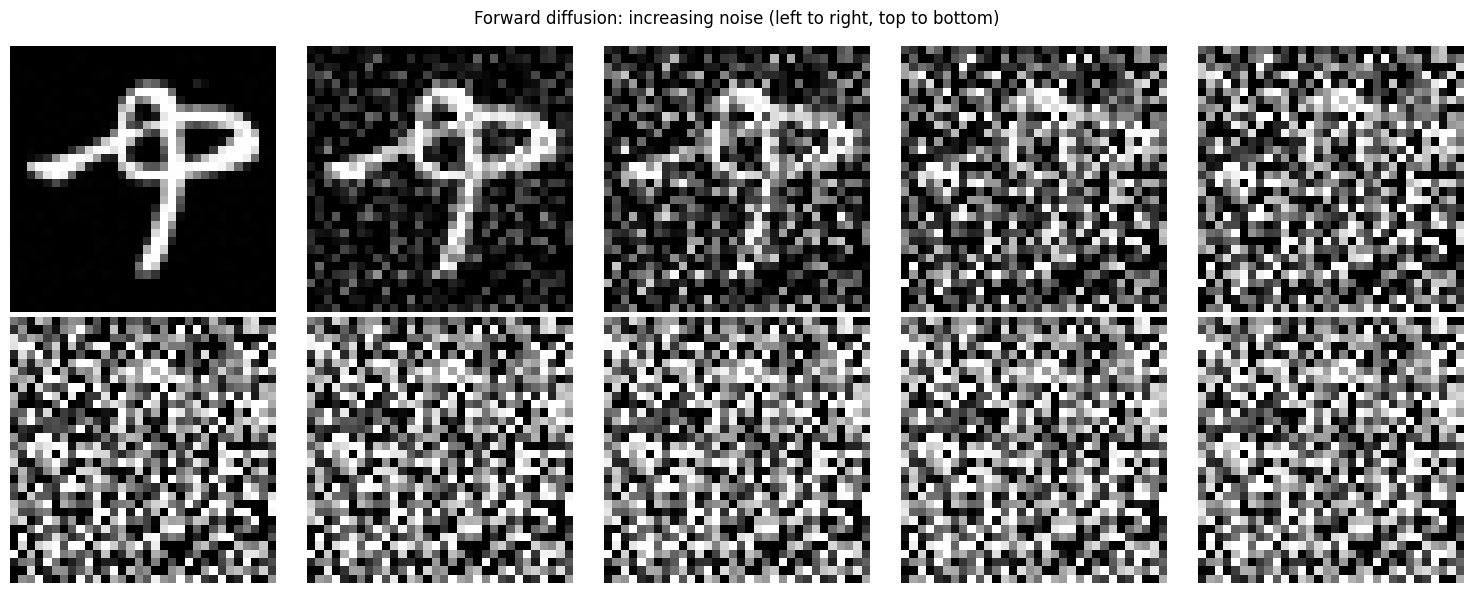

Epoch   1/30 | Noise MSE: 0.31047
Epoch   2/30 | Noise MSE: 0.08456
Epoch   3/30 | Noise MSE: 0.06787
Epoch   4/30 | Noise MSE: 0.06037
Epoch   5/30 | Noise MSE: 0.05703


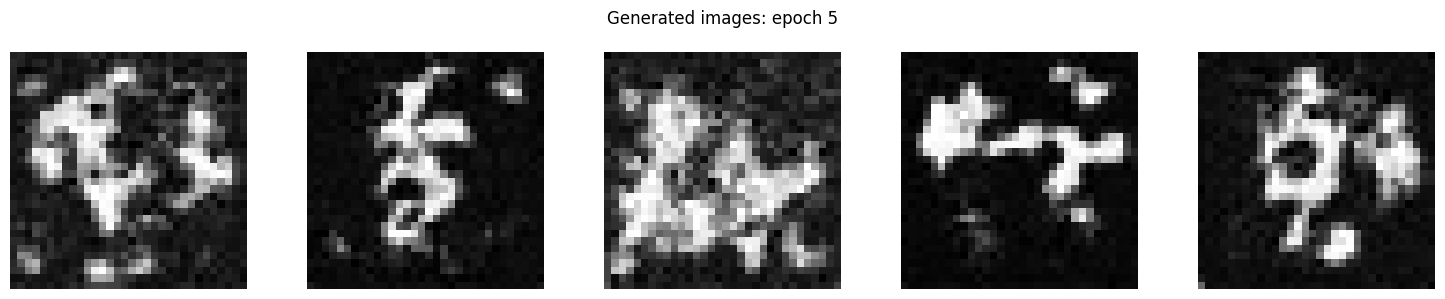

Epoch   6/30 | Noise MSE: 0.05276
Epoch   7/30 | Noise MSE: 0.05299
Epoch   8/30 | Noise MSE: 0.05121
Epoch   9/30 | Noise MSE: 0.04887
Epoch  10/30 | Noise MSE: 0.04842


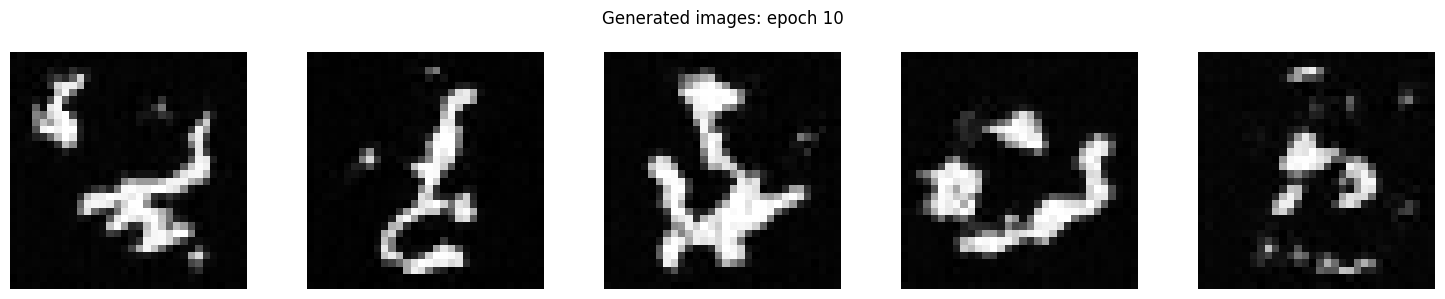

Epoch  11/30 | Noise MSE: 0.04678
Epoch  12/30 | Noise MSE: 0.04677
Epoch  13/30 | Noise MSE: 0.04672
Epoch  14/30 | Noise MSE: 0.04529
Epoch  15/30 | Noise MSE: 0.04361


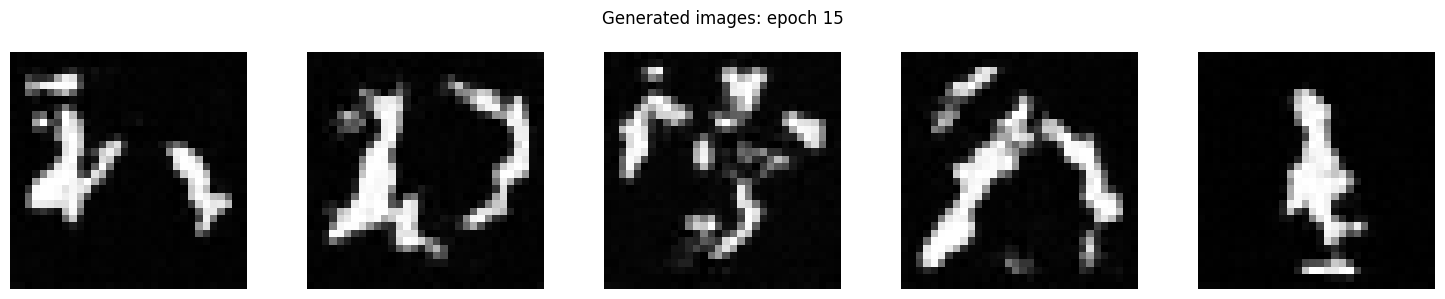

Epoch  16/30 | Noise MSE: 0.04236
Epoch  17/30 | Noise MSE: 0.04252
Epoch  18/30 | Noise MSE: 0.04254
Epoch  19/30 | Noise MSE: 0.04213
Epoch  20/30 | Noise MSE: 0.04167


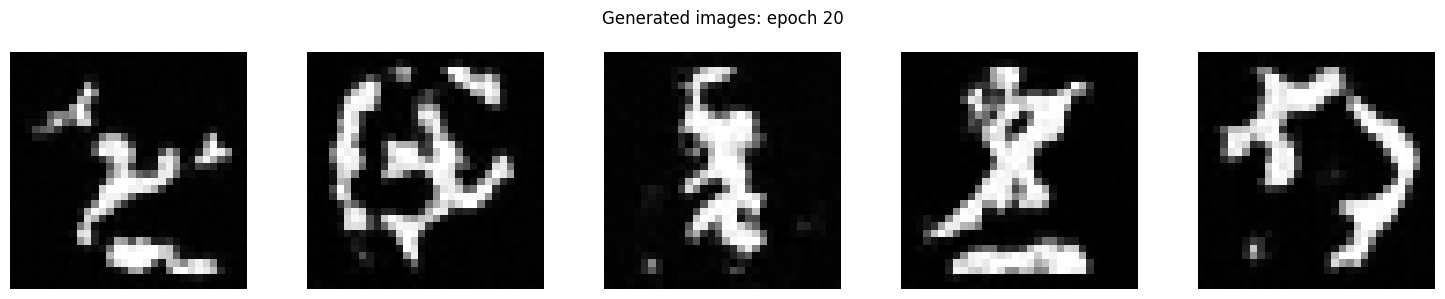

Epoch  21/30 | Noise MSE: 0.04268
Epoch  22/30 | Noise MSE: 0.04098
Epoch  23/30 | Noise MSE: 0.04149
Epoch  24/30 | Noise MSE: 0.04113
Epoch  25/30 | Noise MSE: 0.04079


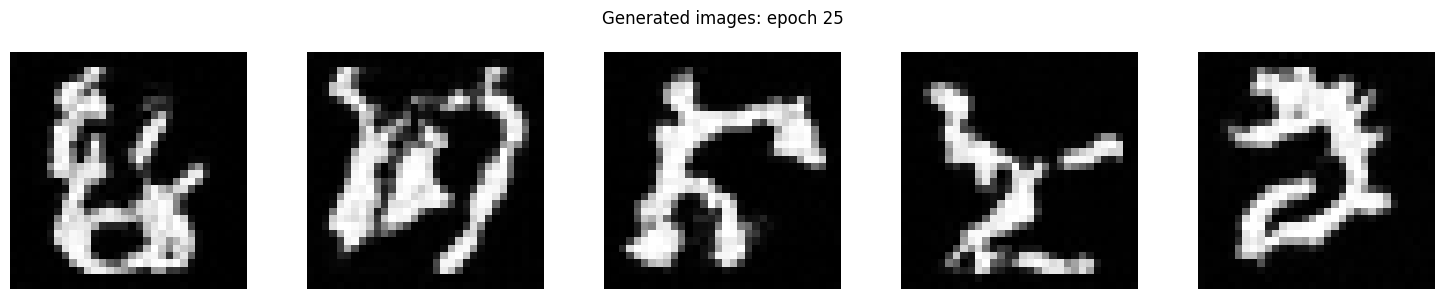

Epoch  26/30 | Noise MSE: 0.04002
Epoch  27/30 | Noise MSE: 0.03981
Epoch  28/30 | Noise MSE: 0.03941
Epoch  29/30 | Noise MSE: 0.03989
Epoch  30/30 | Noise MSE: 0.03847


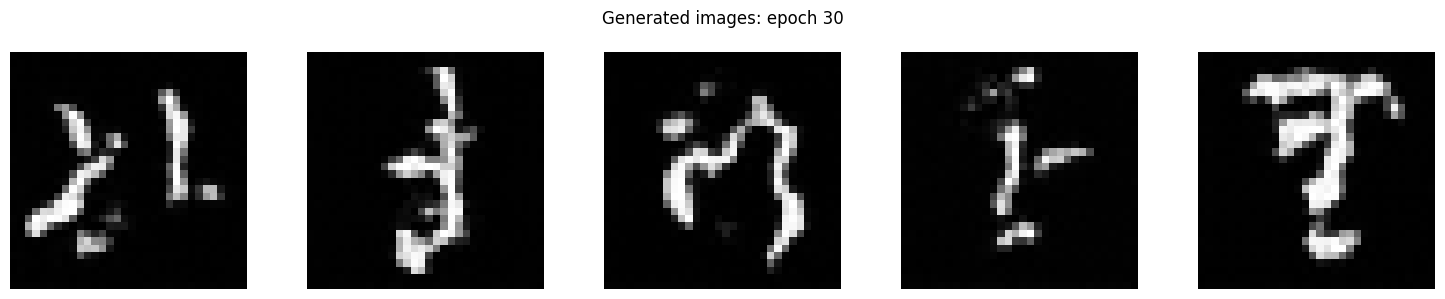

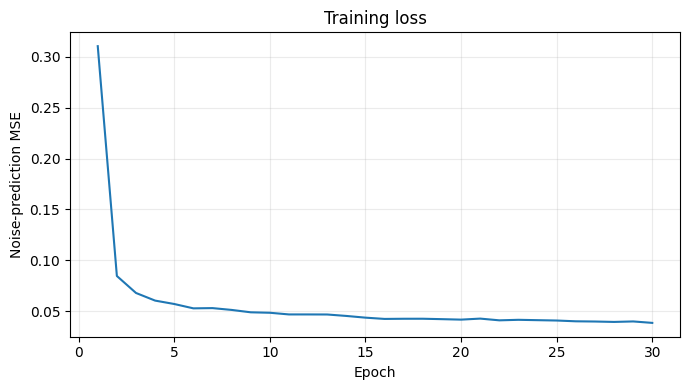

In [10]:
if __name__ == "__main__":
    model, diffusion, history = main()

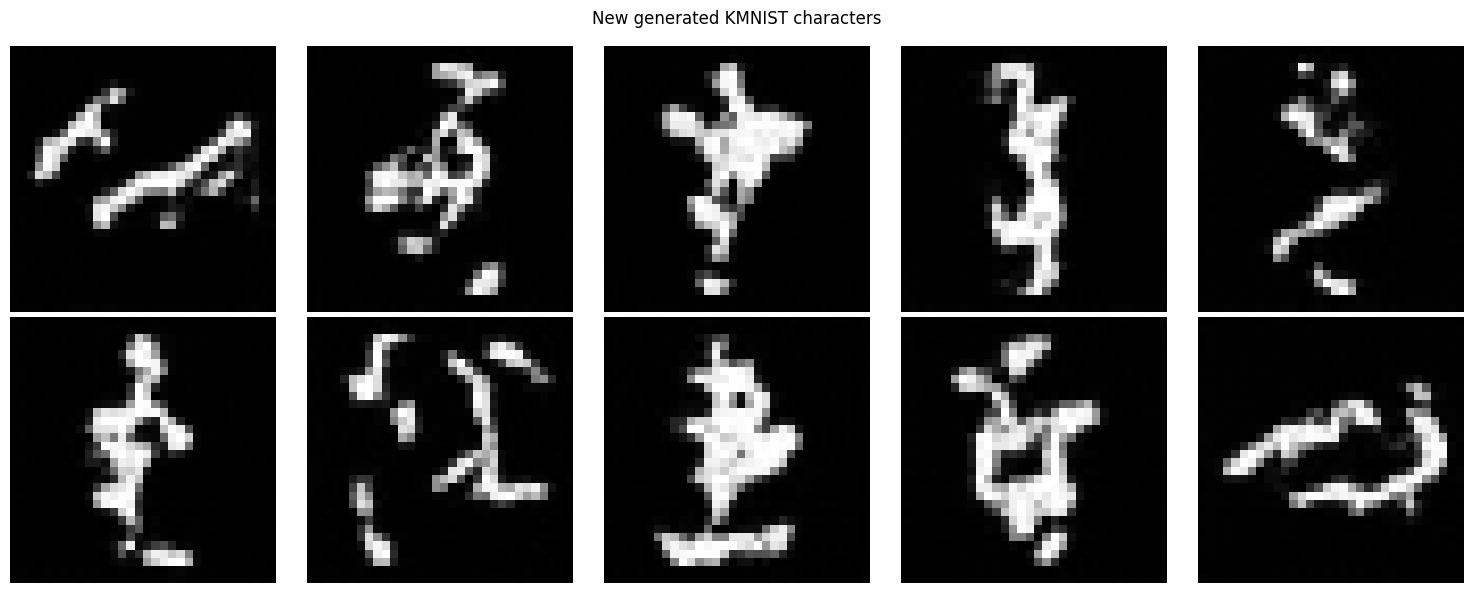

In [11]:
samples = diffusion.sample(
    model,
    shape=(10, IMAGE_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
)

show_images(samples, title="New generated KMNIST characters")